# Bengaluru House Price Prediction

**Final algorithms compared:** Random Forest Regression and HistGradientBoosting Regression.

**Selection rule:** choose the model with the better cross-validation MAE. Random Forest is the preferred final model when its CV performance is competitive. Extra Trees is intentionally not included.

The target is house price in lakhs. Run the notebook from top to bottom. Keep `Bengaluru_House_Data.csv` in the same folder as this notebook, or update the file path below.

## 1. Import libraries

In [37]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

## 2. Load the dataset

In [38]:
# If needed, replace this with the full path to your CSV file.
DATA_PATH = "Bengaluru_House_Data.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


None

## 3. Understand and clean the data

We remove duplicate rows, clean text fields, and convert the target price to numeric. The `total_sqft` parser handles single values, explicit ranges, and common area units. It does not average every number found in a string.

In [39]:
df = df.copy()
df = df.drop_duplicates()

# Remove rows without a usable target.
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

def parse_total_sqft(value):
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower().replace(",", "")
    unit_factors = {
        "sqft": 1.0, "sq.ft": 1.0, "sq ft": 1.0,
        "sqm": 10.7639, "sq.m": 10.7639, "sq meter": 10.7639,
        "sqyd": 9.0, "sq. yards": 9.0, "sq yards": 9.0,
        "acre": 43560.0, "acres": 43560.0,
        "guntha": 1089.0, "cents": 435.6,
        "perch": 272.25, "grounds": 2400.0
    }

    # Convert known unit values, e.g. "100 sqm".
    for unit, factor in unit_factors.items():
        if unit in text:
            match = re.search(r"\d+(?:\.\d+)?", text)
            return float(match.group()) * factor if match else np.nan

    # Explicit numeric range, e.g. "1200 - 1400".
    range_match = re.fullmatch(r"\s*(\d+(?:\.\d+)?)\s*-\s*(\d+(?:\.\d+)?)\s*", text)
    if range_match:
        low, high = map(float, range_match.groups())
        return (low + high) / 2

    # Single numeric value.
    number_match = re.fullmatch(r"\s*\d+(?:\.\d+)?\s*", text)
    if number_match:
        return float(text)

    return np.nan

df["total_sqft"] = df["total_sqft"].apply(parse_total_sqft)
df["bath"] = pd.to_numeric(df["bath"], errors="coerce")
df["balcony"] = pd.to_numeric(df["balcony"], errors="coerce")

# Clean categorical columns.
for col in ["area_type", "availability", "location", "size"]:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

df = df.dropna(subset=["total_sqft", "location"])
df = df[df["total_sqft"] > 0]

print("Shape after basic cleaning:", df.shape)
display(df.head())

Shape after basic cleaning: (12773, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056.0,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600.0,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440.0,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521.0,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200.0,2.0,1.0,51.00


## 4. Feature engineering

In [40]:
# Extract BHK from values such as "2 BHK" or "4 Bedroom".
df["bhk"] = pd.to_numeric(
    df["size"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

df["sqft_per_bhk"] = df["total_sqft"] / df["bhk"].replace(0, np.nan)
df["bath_per_bhk"] = df["bath"] / df["bhk"].replace(0, np.nan)

# Simplify availability into a small number of useful categories.
availability_text = df["availability"].fillna("").astype(str).str.lower()
df["availability_group"] = np.select(
    [
        availability_text.str.contains("ready"),
        availability_text.str.contains(r"\d{4}")
    ],
    ["ready_to_move", "date_or_year"],
    default="other"
)

# Remove original size and availability text after deriving features.
df = df.drop(columns=["size", "availability"])

display(df.head())

,area_type,location,society,total_sqft,bath,balcony,price,bhk,sqft_per_bhk,bath_per_bhk,availability_group
0,Super built-up Area,Electronic City Phase II,Coomee,1056.0,2.0,1.0,39.07,2,528.0,1.0,other
1,Plot Area,Chikka Tirupathi,Theanmp,2600.0,5.0,3.0,120.00,4,650.0,1.25,ready_to_move
2,Built-up Area,Uttarahalli,NaN,1440.0,2.0,3.0,62.00,3,480.0,0.666667,ready_to_move
3,Super built-up Area,Lingadheeranahalli,Soiewre,1521.0,3.0,1.0,95.00,3,507.0,1.0,ready_to_move
4,Super built-up Area,Kothanur,NaN,1200.0,2.0,1.0,51.00,2,600.0,1.0,ready_to_move


## 5. Define features and split the data

The test set is held aside until final evaluation. The location-aware price-per-square-foot filter below is calculated using the training set only; the test set is not filtered using its own target values.

In [41]:
target = "price"
X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training rows before outlier filtering:", len(X_train))
print("Test rows:", len(X_test))

Training rows before outlier filtering: 10218
Test rows: 2555


## 6. Remove extreme training outliers by location

In [42]:
train_for_filter = X_train.copy()
train_for_filter["price"] = y_train

train_for_filter["price_per_sqft"] = (
    train_for_filter["price"] / train_for_filter["total_sqft"]
)

# Use robust median/MAD bounds for locations with enough training examples.
location_stats = train_for_filter.groupby("location")["price_per_sqft"].agg(
    ["median", "count"]
)
location_stats["mad"] = train_for_filter.groupby("location")["price_per_sqft"].apply(
    lambda s: np.median(np.abs(s - np.median(s)))
)

eligible_locations = location_stats[location_stats["count"] >= 8]
location_median = eligible_locations["median"].to_dict()
location_mad = eligible_locations["mad"].replace(0, np.nan).to_dict()

keep_mask = pd.Series(True, index=X_train.index)
for idx, row in train_for_filter.iterrows():
    loc = row["location"]
    if loc in location_median and pd.notna(location_mad.get(loc, np.nan)):
        robust_z = abs(row["price_per_sqft"] - location_median[loc]) / (
            1.4826 * location_mad[loc]
        )
        if robust_z > 4.5:
            keep_mask.loc[idx] = False

X_train = X_train.loc[keep_mask].copy()
y_train = y_train.loc[keep_mask].copy()

print("Training rows after outlier filtering:", len(X_train))
print("Test rows remain unchanged:", len(X_test))

Training rows after outlier filtering: 9780
Test rows remain unchanged: 2555


## 7. Build preprocessing pipeline

In [43]:
numeric_features = [
    "total_sqft", "bath", "balcony", "bhk",
    "sqft_per_bhk", "bath_per_bhk"
]
categorical_features = [
    "area_type", "location", "availability_group"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# TargetEncoder handles the many different location categories while
# learning category information inside the training folds.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", TargetEncoder(
        target_type="continuous",
        smooth="auto",
        cv=3,
        shuffle=True,
        random_state=42
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

## 8. Define the two taught model options

In [44]:
# Log-transforming the target can help with a right-skewed house-price distribution.
random_forest = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(random_state=42, n_jobs=-1))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

hist_gradient_boosting = TransformedTargetRegressor(
    regressor=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingRegressor(random_state=42))
    ]),
    func=np.log1p,
    inverse_func=np.expm1
)

models = {
    "Random Forest": (
        random_forest,
        {
            "regressor__model__n_estimators": [200, 300, 400],
            "regressor__model__max_depth": [None, 15, 25],
            "regressor__model__min_samples_split": [2, 5, 10],
            "regressor__model__min_samples_leaf": [1, 2, 4],
            "regressor__model__max_features": [0.7, 1.0]
        }
    ),
    "HistGradientBoosting": (
        hist_gradient_boosting,
        {
            "regressor__model__learning_rate": [0.03, 0.05, 0.1],
            "regressor__model__max_iter": [150, 250, 350],
            "regressor__model__max_leaf_nodes": [15, 31, 45],
            "regressor__model__l2_regularization": [0.0, 0.1, 1.0]
        }
    )
}

## 9. Hyperparameter tuning with cross-validation

In [45]:
cv = KFold(n_splits=3, shuffle=True, random_state=42)
search_results = {}
best_estimators = []

for model_name, (estimator, parameter_grid) in models.items():
    print(f"Training {model_name} ...")
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=parameter_grid,
        n_iter=4,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )
    search.fit(X_train, y_train)

    search_results[model_name] = search
    best_estimators.append({
        "Model": model_name,
        "CV MAE (lakhs)": -search.best_score_,
        "Best parameters": search.best_params_
    })

cv_results = pd.DataFrame(best_estimators).sort_values("CV MAE (lakhs)")
display(cv_results[["Model", "CV MAE (lakhs)", "Best parameters"]])

Training Random Forest ...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Training HistGradientBoosting ...
Fitting 3 folds for each of 4 candidates, totalling 12 fits


,Model,CV MAE (lakhs),Best parameters
0,Random Forest,29.220694,"{'regressor__model__n_estimators': 300, 'regre..."
1,HistGradientBoosting,29.464462,"{'regressor__model__max_leaf_nodes': 15, 'regr..."


## 10. Compare final test-set performance

In [46]:
test_results = []

for model_name, search in search_results.items():
    predictions = search.best_estimator_.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    test_results.append({
        "Model": model_name,
        "Test MAE (lakhs)": mae,
        "Test RMSE (lakhs)": rmse,
        "Test R2": r2
    })

test_results = pd.DataFrame(test_results).sort_values("Test MAE (lakhs)")
display(test_results)

,Model,Test MAE (lakhs),Test RMSE (lakhs),Test R2
0,Random Forest,30.755156,95.675854,0.671669
1,HistGradientBoosting,31.836618,99.630693,0.643964


## 11. Select the final model

The primary selection measure is **cross-validation MAE** (lower is better). Test metrics are used as a final generalization check, not to tune the model. If Random Forest has a competitive CV MAE and test performance, it is selected as the final algorithm.

In [47]:
best_cv_model_name = cv_results.iloc[0]["Model"]

# Prefer Random Forest when its CV MAE is within 2% of the best CV MAE.
cv_mae_by_model = dict(zip(cv_results["Model"], cv_results["CV MAE (lakhs)"]))
best_cv_mae = min(cv_mae_by_model.values())

if (
    "Random Forest" in cv_mae_by_model
    and cv_mae_by_model["Random Forest"] <= best_cv_mae * 1.02
):
    final_model_name = "Random Forest"
else:
    final_model_name = best_cv_model_name

final_model = search_results[final_model_name].best_estimator_

print("Selected final algorithm:", final_model_name)
print("Reason: competitive/best cross-validation MAE.")

Selected final algorithm: Random Forest
Reason: competitive/best cross-validation MAE.


## 12. Actual vs predicted prices

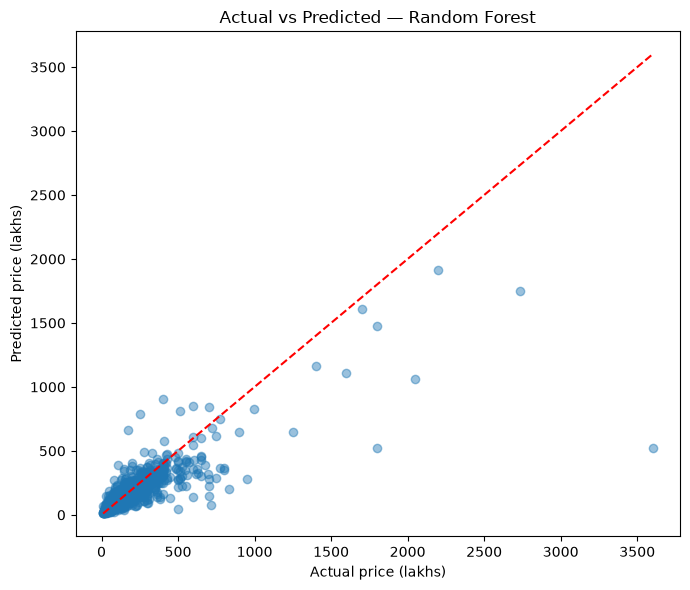

In [48]:
final_predictions = final_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_predictions, alpha=0.45)
min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.xlabel("Actual price (lakhs)")
plt.ylabel("Predicted price (lakhs)")
plt.title(f"Actual vs Predicted — {final_model_name}")
plt.tight_layout()
plt.show()

## 13. Try a sample prediction

In [49]:
# Edit these values to estimate a different property.
sample_house = pd.DataFrame([{
    "area_type": "Super built-up  Area",
    "total_sqft": 1200.0,
    "bath": 2.0,
    "balcony": 1.0,
    "location": "Whitefield",
    "bhk": 2.0,
    "sqft_per_bhk": 600.0,
    "bath_per_bhk": 1.0,
    "availability_group": "ready_to_move"
}])

estimated_price = final_model.predict(sample_house)[0]
print(f"Estimated house price: ₹{estimated_price:.2f} lakhs")

Estimated house price: ₹56.55 lakhs


In [50]:
import joblib

joblib.dump(final_model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


## 14. Conclusion

- Only **Random Forest** and **HistGradientBoosting** are compared.
- Cross-validation MAE is used for model selection.
- The held-out test set is used for the final performance report.
- The selected model is stored in `final_model`.

**Note:** Model scores depend on the dataset and the installed scikit-learn version. Run all cells to obtain the scores for your environment.